# 10.6 · Monitoring, data drift, concept drift, retraining

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/10-deployment-mlops/06-monitoring-drift/lesson.ipynb)

Read the [README](README.md) first. We replay a year of ShopWave: train a churn model on September 2010, then score customers at the start of every month until September 2011, as a production system would, and watch what a monitoring dashboard would have shown.

In [1]:
# --- course files: found locally, downloaded on Colab -------------------------
import sys, urllib.request
from pathlib import Path
REPO_RAW = "https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/"

def repo_file(rel):
    """Return a local path to a file in this repo, downloading it if needed."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / rel).exists():
            return parent / rel
    dest = Path("course_files") / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.exists():
        urllib.request.urlretrieve(REPO_RAW + rel, dest)
    return dest

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
repo_file("data/download.py")                                  # churn_model finds the data through it
sys.path.insert(0, str(repo_file("lib/churn_model.py").parent))
import churn_model as cm

bundle = cm.load_bundle()          # trains and saves models/churn_bundle.joblib the first time
ROOT = cm.repo_root()
print(f"Model trained {bundle['trained']}, test AUC {bundle['metrics']['test_auc']}, "
      f"threshold {bundle['threshold']}")

Model trained 2026-10-28, test AUC 0.741, threshold 0.07


## 1. PSI and KS, by hand

The README's five-bin example: the reference sample had 20% of customers in each bin; this month's sample has 10%, 15%, 20%, 25%, 30%.

In [2]:
expected = np.array([0.20, 0.20, 0.20, 0.20, 0.20])
actual = np.array([0.10, 0.15, 0.20, 0.25, 0.30])
terms = (actual - expected) * np.log(actual / expected)
print(pd.DataFrame({"expected": expected, "actual": actual, "term": terms.round(4)}))
print(f"PSI = {terms.sum():.4f}")

   expected  actual    term
0       0.2    0.10  0.0693
1       0.2    0.15  0.0144
2       0.2    0.20  0.0000
3       0.2    0.25  0.0112
4       0.2    0.30  0.0405
PSI = 0.1354


In [3]:
from scipy.stats import ks_2samp
last_month = [10, 20, 30, 40, 50]
this_month = [30, 40, 50, 60, 70]
result = ks_2samp(last_month, this_month)
print(f"KS distance D = {result.statistic:.2f}, p-value = {result.pvalue:.3f}")

KS distance D = 0.40, p-value = 0.873


## 2. A year of monthly customer tables

Each table is built exactly like the production one: features from the 274 days before the cut-off date, `churned` = no order in the 91 days after it. In real life the labels arrive three months late; here we have them all, so we can check what the dashboard *would* have said against what actually happened.

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

sales = cm.load_sales(both_years=True)         # Dec 2009 - Dec 2011
HISTORY_DAYS = 274                              # same window as the production model (Dec 2010 - Aug 2011)
CUTOFFS = pd.date_range("2010-09-01", "2011-09-01", freq="MS")
tables = {c: cm.build_customer_table(sales, c, lookback_days=HISTORY_DAYS) for c in CUTOFFS}
print(f"{len(tables)} monthly customer tables, {CUTOFFS[0].date()} to {CUTOFFS[-1].date()}")

def new_model():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

13 monthly customer tables, 2010-09-01 to 2011-09-01


In [5]:
train = tables[CUTOFFS[0]]
model = new_model().fit(train[cm.FEATURES], train["churned"])
p_train = model.predict_proba(train[cm.FEATURES])[:, 1]
print(f"trained on {CUTOFFS[0].date()}: {len(train):,} customers, churn rate {train['churned'].mean():.1%}")

trained on 2010-09-01: 3,321 customers, churn rate 41.5%


## 3. The monitoring table

For every month: the input drift of each feature (PSI against the training month), the drift of the model's scores, the average predicted churn, and, three months later, the actual churn rate and the AUC.

In [6]:
rows = []
for cutoff in CUTOFFS[1:]:
    t = tables[cutoff]
    p = model.predict_proba(t[cm.FEATURES])[:, 1]
    row = {"month": cutoff.strftime("%Y-%m"), "customers": len(t)}
    row.update({f"psi_{f}": cm.psi(train[f], t[f]) for f in cm.FEATURES})
    row.update(psi_score=cm.psi(p_train, p), predicted=p.mean(), actual=t["churned"].mean(),
               auc=roc_auc_score(t["churned"], p))
    rows.append(row)
monitor = pd.DataFrame(rows).set_index("month")
monitor.round(3)

,customers,psi_orders,psi_spend,psi_products,psi_tenure_days,psi_days_since_last,psi_score,predicted,actual,auc
month,,,,,,,,,,
2010-10,3398,0.002,0.002,0.001,0.877,0.030,0.009,0.411,0.459,0.715
2010-11,3724,0.000,0.006,0.004,0.249,0.116,0.036,0.401,0.545,0.735
2010-12,3968,0.002,0.012,0.010,0.228,0.157,0.050,0.391,0.648,0.754
2011-01,3898,0.004,0.017,0.008,0.896,0.415,0.023,0.403,0.650,0.771
2011-02,3849,0.003,0.014,0.006,0.262,0.189,0.016,0.413,0.637,0.767
2011-03,3855,0.000,0.013,0.005,0.288,0.201,0.012,0.423,0.611,0.773
2011-04,3916,0.002,0.009,0.004,0.311,0.157,0.035,0.430,0.596,0.762
2011-05,3927,0.003,0.011,0.005,0.424,0.193,0.028,0.435,0.589,0.769
2011-06,3932,0.001,0.016,0.006,0.509,0.193,0.043,0.431,0.610,0.778


## 4. What the alerts would have said

Rule of thumb for PSI: below 0.1 stable, 0.1 to 0.25 **watch**, above 0.25 **act**.

In [7]:
def band(value):
    return "act" if value > 0.25 else "watch" if value > 0.1 else "ok"

alerts = monitor[[c for c in monitor if c.startswith("psi")]].apply(lambda col: col.map(band))
alerts

,psi_orders,psi_spend,psi_products,psi_tenure_days,psi_days_since_last,psi_score
month,,,,,,
2010-10,ok,ok,ok,act,ok,ok
2010-11,ok,ok,ok,watch,watch,ok
2010-12,ok,ok,ok,watch,watch,ok
2011-01,ok,ok,ok,act,act,ok
2011-02,ok,ok,ok,act,watch,ok
2011-03,ok,ok,ok,act,watch,ok
2011-04,ok,ok,ok,act,watch,ok
2011-05,ok,ok,ok,act,watch,ok
2011-06,ok,ok,ok,act,watch,ok


In [8]:
print("months with an 'act' alert:", list(alerts.index[(alerts == "act").any(axis=1)]))
print(f"AUC range over the year: {monitor['auc'].min():.3f} to {monitor['auc'].max():.3f}")
gap = monitor["actual"] - monitor["predicted"]
print(f"largest calibration gap: {gap.max():+.3f} in {gap.idxmax()}")

months with an 'act' alert: ['2010-10', '2011-01', '2011-02', '2011-03', '2011-04', '2011-05', '2011-06', '2011-07', '2011-08']
AUC range over the year: 0.715 to 0.778
largest calibration gap: +0.258 in 2010-12


## 5. The picture

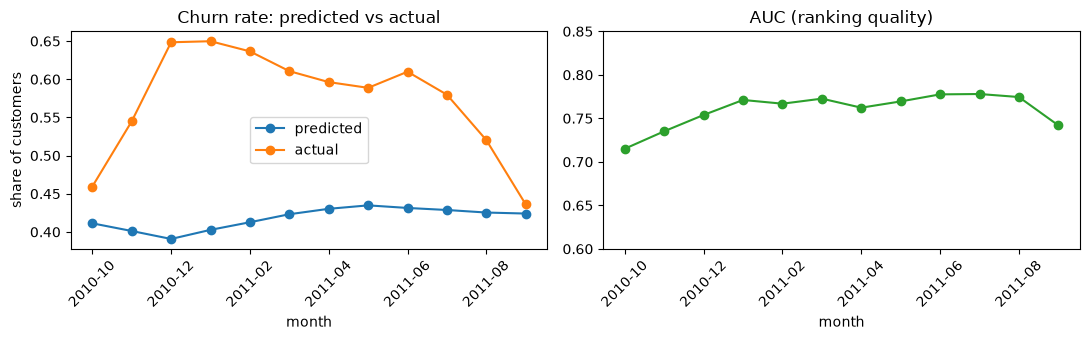

In [9]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
monitor[["predicted", "actual"]].plot(ax=axes[0], marker="o")
axes[0].set_title("Churn rate: predicted vs actual"); axes[0].set_ylabel("share of customers")
monitor["auc"].plot(ax=axes[1], marker="o", color="tab:green")
axes[1].set_title("AUC (ranking quality)"); axes[1].set_ylim(0.6, 0.85)
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

Three stories in one picture and one table:

- **Ranking held.** AUC stayed between 0.715 and 0.778 all year. The model kept putting risky customers above safe ones.
- **Calibration broke.** Through the winter far more customers churned than predicted: 65% against 39% for December. Each customer's *probability* was wrong even though the *order* was right. This is **concept drift**: customers seen on 1 December had just done their Christmas shopping, and most did not return in the quiet months that followed. The same features meant more churn.
- **The loudest alarms were mostly about the calendar, not the customers.** Look at the score PSI: it never left "ok" (at most 0.056), because the model barely uses tenure. The tenure alarms come from where each history window starts:

In [10]:
for cutoff in ["2010-09-01", "2010-10-01", "2011-01-01", "2011-06-01"]:
    t = tables[pd.Timestamp(cutoff)]
    start = pd.Timestamp(cutoff) - pd.Timedelta(days=HISTORY_DAYS)
    print(f"{cutoff}: window starts {start.date()}, {(t['tenure_days'] >= HISTORY_DAYS - 10).mean():.0%} "
          f"of customers at the tenure cap")

2010-09-01: window starts 2009-12-01, 20% of customers at the tenure cap
2010-10-01: window starts 2009-12-31, 4% of customers at the tenure cap
2011-01-01: window starts 2010-04-02, 6% of customers at the tenure cap
2011-06-01: window starts 2010-08-31, 10% of customers at the tenure cap


The training window began on 1 December 2009, in the busy pre-Christmas weeks, so a fifth of the training customers had their first visible order right at its start. October's window began on 31 December 2009, when the shop was closed for the holidays. A real drift alarm, caused by a feature definition, with almost no effect on the scores. Check what an alarm means before acting on it.

The one problem that mattered, calibration, set off no input or score alarm at all. Only the labels, three months later, revealed it.

## 6. A KS test on recency in January

In [11]:
jan = tables[pd.Timestamp("2011-01-01")]
result = ks_2samp(train["days_since_last"], jan["days_since_last"])
print(f"days_since_last, Sept 2010 vs Jan 2011: D = {result.statistic:.3f}, p = {result.pvalue:.1e}")
print(train["days_since_last"].median(), "→", jan["days_since_last"].median(), "days (median)")

days_since_last, Sept 2010 vs Jan 2011: D = 0.122, p = 9.1e-24
71.0 → 59.0 days (median)


With thousands of customers the KS p-value is tiny for almost any change. That is why teams alert on effect sizes (PSI, the KS distance D) rather than p-values.

## 7. Should we retrain on the latest data?

The obvious policy is "retrain every month on the newest labelled data". Test it: on the September 2011 customers, compare the September 2010 model with models retrained on March and June 2011, the newest data available at the time.

In [12]:
target = tables[pd.Timestamp("2011-09-01")]
t35 = 0.35                                   # the cheapest threshold for a £20 voucher (10.7)
rows = []
for trained in ["2010-09-01", "2011-03-01", "2011-06-01"]:
    t = tables[pd.Timestamp(trained)]
    m = new_model().fit(t[cm.FEATURES], t["churned"])
    p = m.predict_proba(target[cm.FEATURES])[:, 1]
    rows.append({"trained on": trained, "AUC": roc_auc_score(target["churned"], p),
                 "predicted": p.mean(), "actual": target["churned"].mean(),
                 "cost at £20 voucher": cm.expected_cost(target["churned"], p, t35, c_voucher=20)})
pd.DataFrame(rows).round(3)

,trained on,AUC,predicted,actual,cost at £20 voucher
0,2010-09-01,0.742,0.424,0.436,56560
1,2011-03-01,0.739,0.607,0.436,58120
2,2011-06-01,0.740,0.593,0.436,58300


All three rank customers equally well. But the models trained on spring and summer think September will look like their own months, and over-predict churn badly; the year-old model, trained in the **same season**, is the best calibrated. When vouchers cost £20 and the threshold matters, that shows up in pounds.

The lesson is not "never retrain". It is: **decide by evidence, on the newest labelled data, with seasonality in mind**. For ShopWave that means comparing a candidate trained on recent months with one trained on the same season last year, and promoting whichever wins (10.5's challenger/champion).

## Quiz answers

1. Data drift: the inputs change (customers buy less often). Concept drift: the relationship between inputs and outcome changes (the same recency means more churn in January).
2. Stable (< 0.1), watch (0.1–0.25), act (> 0.25).
3. Labels arrive late (91 days here); score drift and input drift are available immediately.
4. With thousands of rows, any tiny change is "significant"; effect sizes say whether it matters.
5. Ranking (AUC) can hold while calibration (the level of the probabilities) drifts; threshold decisions depend on calibration.

**Next:** [10.7 Responsible AI](../07-responsible-ai/)